# HT-9046MX — ML Calibration Profiles, Temporal Validation & Leave-One-Machine-Out

Notebook นี้ต่อจาก `HT9046MX_State_Aware_Baseline_Analysis.ipynb` และใช้ผล `baseline_stats.csv` เพื่อ:

- เลือกเครื่อง/โมดูล/SV ที่ข้อมูลเพียงพอ
- สร้าง calibration profile จากช่วงต้น 70% ของเวลาเท่านั้น
- สร้าง relative features: robust z-score, pressure differential, rolling slope และ lag response
- ทำ temporal validation บนช่วงท้าย 30%
- ทำ Leave-One-Machine-Out (LOMO) บนเครื่องที่ข้อมูลเพียงพอ
- กันเครื่องประวัติสั้น/ข้อมูลไม่พอออกเป็น external test โดยไม่ใช้ฝึกหรือ calibrate

ไม่มี failure label ที่ยืนยันแล้ว ผล validation จึงวัด **transferability และ calibration stability** ไม่ใช่ precision/recall ของการตรวจ leak

## 1. Setup

In [1]:
import importlib.util
import json
import os
import subprocess
import sys
import warnings
from pathlib import Path

required = {
    "polars": "polars>=1.20", "pandas": "pandas>=2", "numpy": "numpy>=1.26",
    "sklearn": "scikit-learn>=1.4", "matplotlib": "matplotlib>=3.8", "joblib": "joblib>=1.3",
}
missing = [pkg for module, pkg in required.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import polars as pl
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer

warnings.filterwarnings("ignore", category=RuntimeWarning)
plt.style.use("seaborn-v0_8-whitegrid")

start = Path(os.environ.get("HT9046MX_PROJECT_ROOT", Path.cwd())).resolve()
PROJECT_ROOT = next(
    (p for p in [start, start.parent] if (p / "README_System.md").exists()),
    start,
)
ANALYSIS_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_colab_analysis"
if not ANALYSIS_ROOT.exists():
    ANALYSIS_ROOT = PROJECT_ROOT / "outputs" / "ht9046mx_colab_analysis"
OUTPUT_ROOT = PROJECT_ROOT / "notebooks" / "outputs" / "ht9046mx_ml_calibration"
PROFILE_ROOT = OUTPUT_ROOT / "calibration_profiles"
FIGURE_ROOT = OUTPUT_ROOT / "figures"
for folder in [OUTPUT_ROOT, PROFILE_ROOT, FIGURE_ROOT]:
    folder.mkdir(parents=True, exist_ok=True)

BASELINE_FILE = ANALYSIS_ROOT / "baseline_stats.csv"
READINESS_FILE = ANALYSIS_ROOT / "machine_ml_readiness.csv"
MINUTE_CACHE = ANALYSIS_ROOT / "cache" / "minute_module_state.parquet"
for required_file in [BASELINE_FILE, READINESS_FILE, MINUTE_CACHE]:
    if not required_file.exists():
        raise FileNotFoundError(f"Missing {required_file}. Run the state-aware baseline notebook first.")

RANDOM_STATE = 9046
TIME_TRAIN_FRACTION = 0.70
MIN_READY_MODULES_PER_MACHINE = 6
SETTLE_MINUTES = 3
MODEL_SAMPLE_PER_MACHINE = 12_000
EVAL_SAMPLE_PER_MACHINE = 25_000
MAX_SAMPLES_PER_TREE = 2048
N_TREES = 120

BASE_FEATURES = ["hp1", "lp1", "hp2", "lp2", "valve", "temphi", "templo"]
DERIVED_FEATURES = ["dp1", "dp2", "hp_stage_gap", "lp_stage_gap"]
SLOPE_FEATURES = [f"{name}_slope_15m" for name in BASE_FEATURES]
RESPONSE_TARGETS = ["hp2", "lp2", "templo"]
LAG_FEATURES = []
for lag in [1, 5]:
    LAG_FEATURES.append(f"valve_change_{lag}m")
    for target in RESPONSE_TARGETS:
        LAG_FEATURES += [f"{target}_response_{lag}m", f"valve_to_{target}_gain_{lag}m"]
RAW_FEATURES = BASE_FEATURES + DERIVED_FEATURES + SLOPE_FEATURES + LAG_FEATURES
MODEL_FEATURES = [f"rz_{feature}" for feature in RAW_FEATURES]

print("PROJECT_ROOT:", PROJECT_ROOT)
print("ANALYSIS_ROOT:", ANALYSIS_ROOT)
print("OUTPUT_ROOT:", OUTPUT_ROOT)
print("Model features:", len(MODEL_FEATURES))

PROJECT_ROOT: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P
ANALYSIS_ROOT: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_colab_analysis
OUTPUT_ROOT: C:\Users\Book\OneDrive\Documents\ChatGPT\OPERATION_P\notebooks\outputs\ht9046mx_ml_calibration
Model features: 32


## 2. Split policy

- **Development machines:** อย่างน้อย 6 modules ผ่านเกณฑ์ candidate ในผล readiness เดิม
- **External test machines:** เครื่องอื่นทั้งหมด รวมเครื่องวันน้อยและข้อมูลไม่พอ
- **Profile window:** 70% แรกของวันใน development machine
- **Temporal validation:** 30% หลังของเครื่องเดียวกัน
- **LOMO:** ฝึก shared model จาก development machines อื่น แล้วทดสอบช่วงท้ายของเครื่องที่กันออก
- External test ใช้ fleet cold-start profile ที่สร้างจาก development train window เท่านั้น

In [2]:
baseline_audit = pl.read_csv(BASELINE_FILE, schema_overrides={"machine_number": pl.Utf8})
readiness = pl.read_csv(READINESS_FILE, schema_overrides={"machine_number": pl.Utf8})

development_machines = sorted(
    readiness.filter(pl.col("candidate_modules") >= MIN_READY_MODULES_PER_MACHINE)
    .get_column("machine_number").cast(pl.Utf8).to_list()
)
all_machines = sorted(readiness.get_column("machine_number").cast(pl.Utf8).to_list())
external_test_machines = sorted(set(all_machines) - set(development_machines))

split_manifest = pd.DataFrame({
    "machine_number": all_machines,
    "role": ["development_temporal_lomo" if m in development_machines else "external_test" for m in all_machines],
})
split_manifest.to_csv(OUTPUT_ROOT / "machine_split_manifest.csv", index=False)

print("Development machines:", development_machines)
print("External test machines:", external_test_machines)
display(split_manifest)

Development machines: ['017', '022', '024', '029', '041', '057', '058', '070', '072', '081', '082', '083']
External test machines: ['056', '063', '071', '115', '118', '119', '124']


,machine_number,role
0,017,development_temporal_lomo
1,022,development_temporal_lomo
2,024,development_temporal_lomo
3,029,development_temporal_lomo
4,041,development_temporal_lomo
5,056,external_test
6,057,development_temporal_lomo
7,058,development_temporal_lomo
8,063,external_test
9,070,development_temporal_lomo


## 3. Rebuild evidence-safe operating rows from the minute cache

In [3]:
minute = pl.read_parquet(MINUTE_CACHE).sort(["machine_number", "module", "minute"])
minute = minute.with_columns(pl.col("machine_number").cast(pl.Utf8))
control_states = ["ChangeValve", "MValveHome", "AdjustValve"]

minute = minute.with_columns(
    pl.when(pl.col("global_status") == "Stop").then(pl.lit("GLOBAL_STOP"))
    .when(
        pl.col("module_status").is_in(control_states)
        | (pl.col("busy") == 1)
        | (pl.col("valve") < 0)
    ).then(pl.lit("CONTROL_SEQUENCE"))
    .when(pl.col("module_status") == "Off").then(pl.lit("RUN_MODULE_OFF"))
    .when(
        (pl.col("global_status") == "Run") & (pl.col("module_status") == "On")
        & (pl.col("busy") == 0) & (pl.col("valve") >= 0) & (pl.col("sv") == "Off")
    ).then(pl.lit("RUN_ON_SV_OFF"))
    .when(
        (pl.col("global_status") == "Run") & (pl.col("module_status") == "On")
        & (pl.col("busy") == 0) & (pl.col("valve") >= 0) & (pl.col("sv") == "On")
    ).then(pl.lit("RUN_ON_SV_ON"))
    .otherwise(pl.lit("UNCLASSIFIED")).alias("state")
)

minute = minute.with_columns(
    (
        (pl.col("state") != pl.col("state").shift(1).over(["machine_number", "module"]))
        | (pl.col("minute").diff().over(["machine_number", "module"]).dt.total_minutes() > 2)
    ).fill_null(True).alias("segment_start")
).with_columns(
    pl.col("segment_start").cast(pl.Int64).cum_sum().over(["machine_number", "module"]).alias("segment_id")
).with_columns(
    pl.col("minute").cum_count().over(["machine_number", "module", "segment_id"]).alias("minutes_in_state")
)

eligible = minute.filter(
    pl.col("state").is_in(["RUN_ON_SV_OFF", "RUN_ON_SV_ON"])
    & (pl.col("minutes_in_state") >= SETTLE_MINUTES)
)

# baseline_stats.csv controls which development machine-module-SV groups are trusted enough.
ready_profile_keys = (
    baseline_audit.filter(pl.col("sufficient_baseline"))
    .with_columns(pl.col("machine_number").cast(pl.Utf8))
    .filter(pl.col("machine_number").is_in(development_machines))
    .select(["machine_number", "module", "sv"]).unique()
)
development_rows = eligible.join(ready_profile_keys, on=["machine_number", "module", "sv"], how="inner")
external_rows = eligible.filter(pl.col("machine_number").is_in(external_test_machines))

print(f"Eligible development rows: {development_rows.height:,}")
print(f"Eligible external-test rows: {external_rows.height:,}")

Eligible development rows: 2,406,892
Eligible external-test rows: 258,743


## 4. Temporal split — determine cutoffs before profile calculation

In [4]:
cutoff_rows = []
for machine in development_machines:
    dates = (
        development_rows.filter(pl.col("machine_number") == machine)
        .select(pl.col("minute").dt.date().unique().sort())
        .to_series().to_list()
    )
    if len(dates) < 2:
        continue
    split_index = min(len(dates) - 2, max(0, int(np.ceil(len(dates) * TIME_TRAIN_FRACTION)) - 1))
    cutoff_rows.append({
        "machine_number": machine,
        "cutoff_date": dates[split_index],
        "total_days": len(dates),
        "train_days": split_index + 1,
        "validation_days": len(dates) - split_index - 1,
    })

cutoffs = pl.from_pandas(pd.DataFrame(cutoff_rows)).with_columns(pl.col("machine_number").cast(pl.Utf8))
cutoffs.write_csv(OUTPUT_ROOT / "temporal_cutoffs.csv")
development_rows = development_rows.join(cutoffs.select(["machine_number", "cutoff_date"]), on="machine_number")
development_rows = development_rows.with_columns(
    (pl.col("minute").dt.date() <= pl.col("cutoff_date")).alias("is_profile_train")
)
display(cutoffs.to_pandas())

,machine_number,cutoff_date,total_days,train_days,validation_days
0,017,2026-08-26,23,17,6
1,022,2026-08-26,21,15,6
2,024,2026-08-25,17,12,5
3,029,2026-08-24,29,21,8
4,041,2026-08-22,27,19,8
5,057,2026-08-25,21,15,6
6,058,2026-08-24,29,21,8
7,070,2026-08-24,24,17,7
8,072,2026-08-19,17,12,5
9,081,2026-08-24,25,18,7


## 5. Feature engineering — only present and past observations

In [5]:
def add_raw_features(frame: pl.DataFrame) -> pl.DataFrame:
    frame = frame.sort(["machine_number", "module", "sv", "segment_id", "minute"])
    groups = ["machine_number", "module", "sv", "segment_id"]
    frame = frame.with_columns(
        (pl.col("hp1") - pl.col("lp1")).alias("dp1"),
        (pl.col("hp2") - pl.col("lp2")).alias("dp2"),
        (pl.col("hp2") - pl.col("hp1")).alias("hp_stage_gap"),
        (pl.col("lp2") - pl.col("lp1")).alias("lp_stage_gap"),
    )

    lag15_time = pl.col("minute").shift(15).over(groups)
    gap15 = (pl.col("minute") - lag15_time).dt.total_minutes()
    slope_exprs = []
    for feature in BASE_FEATURES:
        slope_exprs.append(
            pl.when(gap15 == 15)
            .then((pl.col(feature) - pl.col(feature).shift(15).over(groups)) / 15.0)
            .otherwise(None).alias(f"{feature}_slope_15m")
        )
    frame = frame.with_columns(*slope_exprs)

    for lag in [1, 5]:
        lag_time = pl.col("minute").shift(lag).over(groups)
        gap = (pl.col("minute") - lag_time).dt.total_minutes()
        valve_change = pl.when(gap == lag).then(
            pl.col("valve") - pl.col("valve").shift(lag).over(groups)
        ).otherwise(None)
        expressions = [valve_change.alias(f"valve_change_{lag}m")]
        for target in RESPONSE_TARGETS:
            response = pl.when(gap == lag).then(
                pl.col(target) - pl.col(target).shift(lag).over(groups)
            ).otherwise(None)
            expressions += [
                response.alias(f"{target}_response_{lag}m"),
                (response / (valve_change.abs() + 1.0)).alias(f"valve_to_{target}_gain_{lag}m"),
            ]
        frame = frame.with_columns(*expressions)
    return frame

development_features = add_raw_features(development_rows)
external_features = add_raw_features(external_rows)
print("Raw engineered features:", len(RAW_FEATURES))
display(development_features.select(["machine_number", "module", "sv", "minute", *RAW_FEATURES[:12]]).head(8).to_pandas())

Raw engineered features: 32


,machine_number,module,sv,minute,hp1,lp1,hp2,lp2,valve,temphi,templo,dp1,dp2,hp_stage_gap,lp_stage_gap,hp1_slope_15m
0,017,1,Off,2026-08-06 00:02:00,157.8,27.2,190.8,13.3,88.0,70.2,-68.1,130.6,177.5,33.0,-13.9,NaN
1,017,1,Off,2026-08-06 00:03:00,157.9,27.2,190.9,13.3,88.0,70.3,-68.0,130.7,177.6,33.0,-13.9,NaN
2,017,1,Off,2026-08-06 00:04:00,157.8,27.1,190.9,13.3,88.0,70.3,-68.0,130.7,177.6,33.1,-13.8,NaN
3,017,1,Off,2026-08-06 00:05:00,157.7,26.8,190.5,13.5,88.0,70.3,-68.1,130.9,177.0,32.8,-13.3,NaN
4,017,1,Off,2026-08-06 00:06:00,157.7,26.9,190.3,13.4,88.0,70.3,-68.1,130.8,176.9,32.6,-13.5,NaN
5,017,1,Off,2026-08-06 00:07:00,157.8,27.0,190.1,13.3,88.0,70.3,-68.1,130.8,176.8,32.3,-13.7,NaN
6,017,1,Off,2026-08-06 00:08:00,157.8,27.0,190.3,13.4,88.0,70.2,-68.1,130.8,176.9,32.5,-13.6,NaN
7,017,1,Off,2026-08-06 00:09:00,157.7,27.0,190.5,13.3,88.0,70.2,-68.0,130.7,177.2,32.8,-13.7,NaN


## 6. Build leakage-safe calibration profiles from the early window

In [6]:
PROFILE_KEYS = ["machine_number", "module", "sv"]
profile_train = development_features.filter(pl.col("is_profile_train"))

summary_exprs = [pl.len().alias("n_minutes"), pl.col("minute").dt.date().n_unique().alias("n_days")]
for feature in RAW_FEATURES:
    summary_exprs += [
        pl.col(feature).median().alias(f"{feature}__median"),
        pl.col(feature).quantile(0.25).alias(f"{feature}__q25"),
        pl.col(feature).quantile(0.75).alias(f"{feature}__q75"),
        pl.col(feature).quantile(0.05).alias(f"{feature}__q05"),
        pl.col(feature).quantile(0.95).alias(f"{feature}__q95"),
    ]

profile_summary = profile_train.group_by(PROFILE_KEYS).agg(*summary_exprs)
center_cols = PROFILE_KEYS + [f"{feature}__median" for feature in RAW_FEATURES]
with_centers = profile_train.join(profile_summary.select(center_cols), on=PROFILE_KEYS)
mad_exprs = [
    (pl.col(feature) - pl.col(f"{feature}__median")).abs().median().alias(f"{feature}__mad")
    for feature in RAW_FEATURES
]
profile_mad = with_centers.group_by(PROFILE_KEYS).agg(*mad_exprs)
profiles = profile_summary.join(profile_mad, on=PROFILE_KEYS).sort(PROFILE_KEYS)
profiles.write_csv(OUTPUT_ROOT / "machine_module_sv_calibration_profiles.csv")

# Fleet profile is learned only from development training rows and is used for cold-start external tests.
FLEET_KEYS = ["module", "sv"]
fleet_exprs = []
for feature in RAW_FEATURES:
    fleet_exprs += [
        pl.col(feature).median().alias(f"{feature}__median"),
        pl.col(feature).quantile(0.25).alias(f"{feature}__q25"),
        pl.col(feature).quantile(0.75).alias(f"{feature}__q75"),
        pl.col(feature).quantile(0.05).alias(f"{feature}__q05"),
        pl.col(feature).quantile(0.95).alias(f"{feature}__q95"),
    ]
fleet_summary = profile_train.group_by(FLEET_KEYS).agg(pl.len().alias("n_minutes"), *fleet_exprs)
fleet_centers = FLEET_KEYS + [f"{feature}__median" for feature in RAW_FEATURES]
fleet_with_centers = profile_train.join(fleet_summary.select(fleet_centers), on=FLEET_KEYS)
fleet_mad = fleet_with_centers.group_by(FLEET_KEYS).agg(*[
    (pl.col(feature) - pl.col(f"{feature}__median")).abs().median().alias(f"{feature}__mad")
    for feature in RAW_FEATURES
])
fleet_profiles = fleet_summary.join(fleet_mad, on=FLEET_KEYS).sort(FLEET_KEYS)
fleet_profiles.write_csv(OUTPUT_ROOT / "fleet_cold_start_profiles.csv")

display(profiles.select([*PROFILE_KEYS, "n_minutes", "n_days", "hp2__median", "hp2__mad", "valve__median", "valve__mad"]).head(24).to_pandas())

,machine_number,module,sv,n_minutes,n_days,hp2__median,hp2__mad,valve__median,valve__mad
0,017,1,Off,20243,15,194.90,2.60,102.0,0.0
1,017,1,On,197,5,300.10,25.80,97.0,5.0
2,017,2,Off,20270,15,203.60,0.80,92.0,0.0
3,017,2,On,196,5,220.85,7.40,84.0,0.0
4,017,3,Off,20259,15,215.50,1.60,90.0,0.0
5,017,3,On,196,5,228.75,4.70,82.0,0.0
6,017,4,Off,20273,15,198.10,1.30,88.0,0.0
7,017,4,On,1864,8,205.80,0.90,65.0,0.0
8,017,5,Off,20304,15,196.60,1.60,85.0,0.0
9,017,5,On,215,5,196.80,1.20,85.0,0.0


## 7. Save one JSON calibration profile per development machine

In [7]:
profiles_pdf = profiles.to_pandas()
cutoffs_pdf = cutoffs.to_pandas().set_index("machine_number")

for machine in development_machines:
    rows = profiles_pdf[profiles_pdf["machine_number"] == machine]
    payload = {
        "machine_number": machine,
        "source": "baseline_stats.csv eligibility + first 70% temporal profile window",
        "cutoff_date": str(cutoffs_pdf.loc[machine, "cutoff_date"]),
        "profile_version": "state-aware-relative-v1",
        "features": RAW_FEATURES,
        "profiles": [],
    }
    for row in rows.to_dict(orient="records"):
        profile = {
            "module": int(row["module"]), "sv": row["sv"],
            "n_minutes": int(row["n_minutes"]), "n_days": int(row["n_days"]),
            "statistics": {},
        }
        for feature in RAW_FEATURES:
            profile["statistics"][feature] = {
                key: (None if pd.isna(row[f"{feature}__{key}"]) else float(row[f"{feature}__{key}"]))
                for key in ["median", "mad", "q25", "q75", "q05", "q95"]
            }
        payload["profiles"].append(profile)
    (PROFILE_ROOT / f"machine_{machine}_calibration.json").write_text(
        json.dumps(payload, ensure_ascii=False, indent=2), encoding="utf-8"
    )

print(f"Saved {len(list(PROFILE_ROOT.glob('machine_*_calibration.json')))} machine profiles")

Saved 12 machine profiles


## 8. Convert raw features to robust relative features

In [8]:
def apply_profiles(frame: pl.DataFrame, profile_table: pl.DataFrame, keys, profile_source: str) -> pl.DataFrame:
    needed = list(keys)
    for feature in RAW_FEATURES:
        needed += [f"{feature}__median", f"{feature}__mad", f"{feature}__q25", f"{feature}__q75"]
    result = frame.join(profile_table.select(needed), on=list(keys), how="inner")
    expressions = []
    for feature in RAW_FEATURES:
        iqr_scale = (pl.col(f"{feature}__q75") - pl.col(f"{feature}__q25")) / 1.349
        scale = (
            pl.when(pl.col(f"{feature}__mad") > 1e-9).then(pl.col(f"{feature}__mad") / 0.67448975)
            .when(iqr_scale > 1e-9).then(iqr_scale)
            .otherwise(1.0)
        )
        expressions.append(
            ((pl.col(feature) - pl.col(f"{feature}__median")) / scale)
            .clip(-12, 12).alias(f"rz_{feature}")
        )
    return result.with_columns(*expressions, pl.lit(profile_source).alias("profile_source"))

development_relative = apply_profiles(development_features, profiles, PROFILE_KEYS, "machine_early_window")
external_relative = apply_profiles(external_features, fleet_profiles, FLEET_KEYS, "fleet_cold_start")

model_rows = pl.concat([
    development_relative.select(["machine_number", "module", "sv", "minute", "is_profile_train", "profile_source", *MODEL_FEATURES]),
    external_relative.with_columns(pl.lit(False).alias("is_profile_train")).select(
        ["machine_number", "module", "sv", "minute", "is_profile_train", "profile_source", *MODEL_FEATURES]
    ),
], how="vertical")
model_rows.write_parquet(OUTPUT_ROOT / "ml_relative_features.parquet", compression="zstd")

print(f"Development relative rows: {development_relative.height:,}")
print(f"External relative rows: {external_relative.height:,}")

Development relative rows: 2,406,892
External relative rows: 258,743


## 9. Shared anomaly model and evaluation helpers

In [9]:
def to_model_frame(frame: pl.DataFrame) -> pd.DataFrame:
    return frame.select(["machine_number", "module", "sv", "minute", *MODEL_FEATURES]).to_pandas()

def balanced_sample(pdf: pd.DataFrame, machines, per_machine, seed):
    parts = []
    for machine in machines:
        part = pdf[pdf["machine_number"] == machine]
        if part.empty:
            continue
        parts.append(part.sample(n=min(per_machine, len(part)), random_state=seed))
    return pd.concat(parts, ignore_index=True) if parts else pd.DataFrame(columns=pdf.columns)

def fit_detector(train_pdf: pd.DataFrame, seed=RANDOM_STATE):
    imputer = SimpleImputer(strategy="median")
    x = imputer.fit_transform(train_pdf[MODEL_FEATURES])
    detector = IsolationForest(
        n_estimators=N_TREES, max_samples=min(MAX_SAMPLES_PER_TREE, len(x)),
        contamination="auto", random_state=seed, n_jobs=-1,
    )
    detector.fit(x)
    train_scores = detector.decision_function(x)
    thresholds = {
        "watch": float(np.quantile(train_scores, 0.025)),
        "alert": float(np.quantile(train_scores, 0.010)),
    }
    return imputer, detector, thresholds

def score_frame(pdf, imputer, detector, thresholds):
    if pdf.empty:
        return pdf.assign(anomaly_score=np.nan, watch=False, alert=False)
    scores = detector.decision_function(imputer.transform(pdf[MODEL_FEATURES]))
    result = pdf.copy()
    result["anomaly_score"] = scores
    result["watch"] = scores <= thresholds["watch"]
    result["alert"] = scores <= thresholds["alert"]
    return result

development_pdf = to_model_frame(development_relative)
development_pdf["is_profile_train"] = development_relative.get_column("is_profile_train").to_numpy()
external_pdf = to_model_frame(external_relative)

global_train = balanced_sample(
    development_pdf[development_pdf["is_profile_train"]], development_machines,
    MODEL_SAMPLE_PER_MACHINE, RANDOM_STATE,
)
imputer, detector, thresholds = fit_detector(global_train)

model_bundle = {
    "imputer": imputer, "detector": detector, "thresholds": thresholds,
    "model_features": MODEL_FEATURES, "raw_features": RAW_FEATURES,
    "development_machines": development_machines,
    "external_test_machines": external_test_machines,
    "validation_design": "70/30 temporal + leave-one-machine-out + external cold-start test",
}
joblib.dump(model_bundle, OUTPUT_ROOT / "shared_relative_isolation_forest.joblib")
print("Thresholds:", thresholds)

Thresholds: {'watch': -0.001941554633900326, 'alert': -0.06321341404245519}


## 10. Temporal validation on the final 30% of each development machine

In [10]:
temporal_rows = []
for machine in development_machines:
    late = development_pdf[
        (development_pdf["machine_number"] == machine) & (~development_pdf["is_profile_train"])
    ]
    late = late.sample(n=min(EVAL_SAMPLE_PER_MACHINE, len(late)), random_state=RANDOM_STATE)
    scored = score_frame(late, imputer, detector, thresholds)
    temporal_rows.append({
        "machine_number": machine, "n_scored": len(scored),
        "watch_rate_pct": 100 * scored["watch"].mean(),
        "alert_rate_pct": 100 * scored["alert"].mean(),
        "median_score": scored["anomaly_score"].median(),
    })

temporal_validation = pd.DataFrame(temporal_rows)
temporal_validation.to_csv(OUTPUT_ROOT / "temporal_validation.csv", index=False)
display(temporal_validation.sort_values("alert_rate_pct", ascending=False))

,machine_number,n_scored,watch_rate_pct,alert_rate_pct,median_score
3,029,25000,8.772,2.908,0.161918
6,058,25000,3.508,1.980,0.171365
8,072,25000,2.648,1.744,0.165901
10,082,25000,3.700,1.568,0.153008
0,017,25000,3.272,1.152,0.161225
1,022,25000,2.464,0.948,0.160218
5,057,25000,2.920,0.936,0.166714
4,041,25000,2.336,0.736,0.162822
11,083,25000,1.760,0.440,0.166103
7,070,25000,1.076,0.432,0.170642


## 11. Leave-One-Machine-Out validation

In [11]:
lomo_rows = []
for fold, held_out in enumerate(development_machines, start=1):
    fold_train_machines = [m for m in development_machines if m != held_out]
    fold_train = balanced_sample(
        development_pdf[development_pdf["is_profile_train"]], fold_train_machines,
        MODEL_SAMPLE_PER_MACHINE, RANDOM_STATE + fold,
    )
    fold_imputer, fold_detector, fold_thresholds = fit_detector(fold_train, RANDOM_STATE + fold)
    held_out_late = development_pdf[
        (development_pdf["machine_number"] == held_out) & (~development_pdf["is_profile_train"])
    ]
    held_out_late = held_out_late.sample(
        n=min(EVAL_SAMPLE_PER_MACHINE, len(held_out_late)), random_state=RANDOM_STATE + fold
    )
    scored = score_frame(held_out_late, fold_imputer, fold_detector, fold_thresholds)
    lomo_rows.append({
        "held_out_machine": held_out, "train_machines": len(fold_train_machines),
        "n_scored": len(scored),
        "watch_rate_pct": 100 * scored["watch"].mean(),
        "alert_rate_pct": 100 * scored["alert"].mean(),
        "median_score": scored["anomaly_score"].median(),
        "watch_threshold": fold_thresholds["watch"],
        "alert_threshold": fold_thresholds["alert"],
    })
    print(f"LOMO {fold:02d}/{len(development_machines)}: held out {held_out}")

lomo_validation = pd.DataFrame(lomo_rows)
lomo_validation.to_csv(OUTPUT_ROOT / "lomo_validation.csv", index=False)
display(lomo_validation.sort_values("alert_rate_pct", ascending=False))

LOMO 01/12: held out 017


LOMO 02/12: held out 022


LOMO 03/12: held out 024


LOMO 04/12: held out 029


LOMO 05/12: held out 041


...

LOMO 09/12: held out 072


LOMO 10/12: held out 081


LOMO 11/12: held out 082


LOMO 12/12: held out 083


,held_out_machine,train_machines,n_scored,watch_rate_pct,alert_rate_pct,median_score,watch_threshold,alert_threshold
3,029,11,25000,8.684,3.104,0.161577,-0.002814,-0.066690
6,058,11,25000,3.772,2.140,0.172204,0.012328,-0.054612
10,082,11,25000,5.312,1.864,0.157093,-0.000626,-0.065188
8,072,11,25000,2.540,1.740,0.163634,-0.005407,-0.064450
0,017,11,25000,3.216,1.120,0.160419,-0.003845,-0.063676
5,057,11,25000,2.920,0.992,0.167801,-0.000963,-0.067320
4,041,11,25000,2.524,0.772,0.163092,-0.005032,-0.068408
1,022,11,25000,2.840,0.672,0.159168,-0.007884,-0.071984
7,070,11,25000,1.004,0.412,0.168214,-0.009177,-0.076368
11,083,11,25000,1.824,0.388,0.165650,-0.005569,-0.066913


## 12. External test — short-history and insufficient-data machines

In [12]:
external_rows_summary = []
for machine in external_test_machines:
    test = external_pdf[external_pdf["machine_number"] == machine]
    test = test.sample(n=min(EVAL_SAMPLE_PER_MACHINE, len(test)), random_state=RANDOM_STATE)
    scored = score_frame(test, imputer, detector, thresholds)
    external_rows_summary.append({
        "machine_number": machine, "n_scored": len(scored),
        "profile_source": "fleet_cold_start",
        "watch_rate_pct": 100 * scored["watch"].mean(),
        "alert_rate_pct": 100 * scored["alert"].mean(),
        "median_score": scored["anomaly_score"].median(),
    })

external_test = pd.DataFrame(external_rows_summary)
external_test.to_csv(OUTPUT_ROOT / "external_test_results.csv", index=False)
display(external_test.sort_values("alert_rate_pct", ascending=False))

,machine_number,n_scored,profile_source,watch_rate_pct,alert_rate_pct,median_score
6,124,25000,fleet_cold_start,37.444000,22.616000,0.032506
2,071,25000,fleet_cold_start,25.328000,15.192000,0.155087
5,119,25000,fleet_cold_start,22.108000,12.248000,0.077035
3,115,25000,fleet_cold_start,13.504000,10.344000,0.159765
4,118,25000,fleet_cold_start,17.152000,5.580000,0.077458
0,056,25000,fleet_cold_start,8.720000,3.436000,0.168070
1,063,1904,fleet_cold_start,11.502101,3.256303,0.137219


## 13. Validation charts

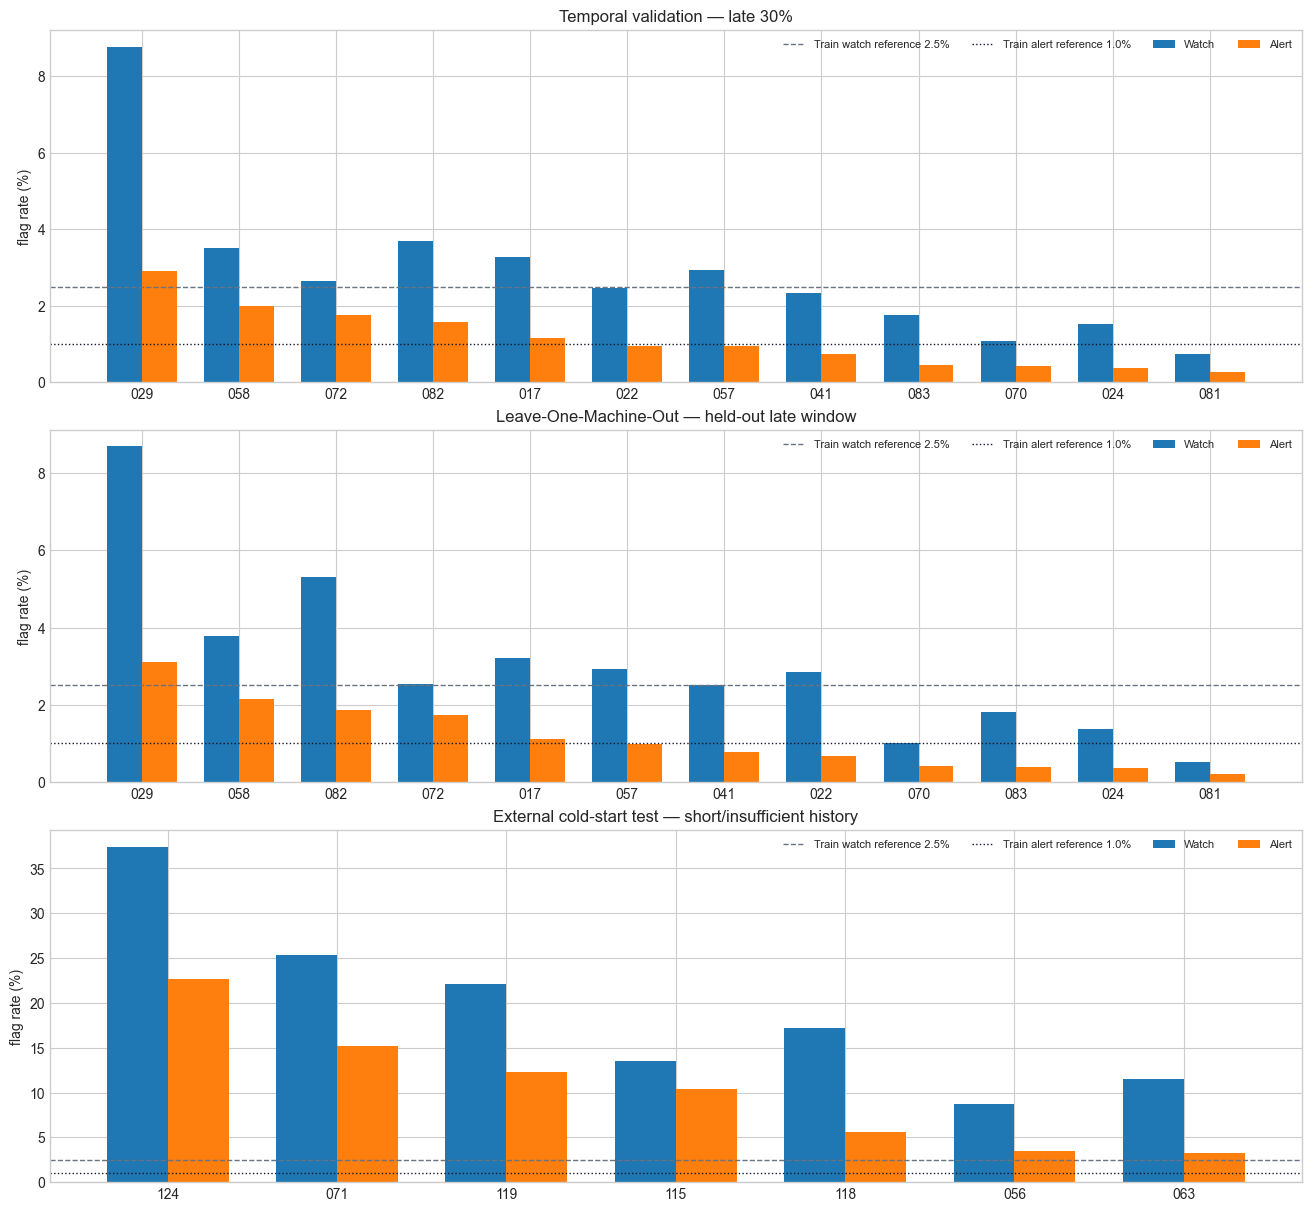

In [13]:
fig, axes = plt.subplots(3, 1, figsize=(13, 12), constrained_layout=True)

for ax, table, label_col, title in [
    (axes[0], temporal_validation, "machine_number", "Temporal validation — late 30%"),
    (axes[1], lomo_validation, "held_out_machine", "Leave-One-Machine-Out — held-out late window"),
    (axes[2], external_test, "machine_number", "External cold-start test — short/insufficient history"),
]:
    ordered = table.sort_values("alert_rate_pct", ascending=False)
    x = np.arange(len(ordered))
    ax.bar(x - 0.18, ordered["watch_rate_pct"], width=0.36, label="Watch")
    ax.bar(x + 0.18, ordered["alert_rate_pct"], width=0.36, label="Alert")
    ax.axhline(2.5, color="#6b7280", ls="--", lw=1, label="Train watch reference 2.5%")
    ax.axhline(1.0, color="#111827", ls=":", lw=1, label="Train alert reference 1.0%")
    ax.set_xticks(x, ordered[label_col].astype(str))
    ax.set_ylabel("flag rate (%)")
    ax.set_title(title)
    ax.legend(ncol=4, fontsize=8)

fig.savefig(FIGURE_ROOT / "01_validation_flag_rates.png", dpi=170, bbox_inches="tight")
plt.show()

## 14. Feature-family portability

In [14]:
family_map = {}
for feature in MODEL_FEATURES:
    raw = feature.removeprefix("rz_")
    if raw in BASE_FEATURES:
        family_map[feature] = "robust level"
    elif raw in DERIVED_FEATURES:
        family_map[feature] = "pressure differential"
    elif "slope" in raw:
        family_map[feature] = "rolling slope"
    else:
        family_map[feature] = "lag response"

late_all = development_pdf[~development_pdf["is_profile_train"]]
portability_rows = []
for feature in MODEL_FEATURES:
    machine_medians = late_all.groupby("machine_number")[feature].median()
    portability_rows.append({
        "feature": feature,
        "family": family_map[feature],
        "between_machine_iqr_of_late_medians": machine_medians.quantile(0.75) - machine_medians.quantile(0.25),
        "median_abs_late_value": late_all[feature].abs().median(),
        "missing_pct": 100 * late_all[feature].isna().mean(),
    })

feature_portability = pd.DataFrame(portability_rows).sort_values("between_machine_iqr_of_late_medians")
feature_portability.to_csv(OUTPUT_ROOT / "feature_portability.csv", index=False)
display(feature_portability)

family_summary = feature_portability.groupby("family", as_index=False).agg(
    median_between_machine_iqr=("between_machine_iqr_of_late_medians", "median"),
    median_abs_value=("median_abs_late_value", "median"),
    median_missing_pct=("missing_pct", "median"),
)
display(family_summary.sort_values("median_between_machine_iqr"))

,feature,family,between_machine_iqr_of_late_medians,median_abs_late_value,missing_pct
4,rz_valve,robust level,0.000000,0.000000,0.000000
13,rz_hp2_slope_15m,rolling slope,0.000000,0.674490,3.717480
14,rz_lp2_slope_15m,rolling slope,0.000000,0.674490,3.717480
15,rz_valve_slope_15m,rolling slope,0.000000,0.000000,3.717480
12,rz_lp1_slope_15m,rolling slope,0.000000,0.674490,3.717480
11,rz_hp1_slope_15m,rolling slope,0.000000,0.899320,3.717480
25,rz_valve_change_5m,lag response,0.000000,0.000000,0.881831
24,rz_valve_to_templo_gain_1m,lag response,0.000000,0.100000,0.181804
23,rz_templo_response_1m,lag response,0.000000,0.100000,0.181804
22,rz_valve_to_lp2_gain_1m,lag response,0.000000,0.674490,0.181804


,family,median_between_machine_iqr,median_abs_value,median_missing_pct
0,lag response,0.000000,0.674490,0.531817
3,rolling slope,0.000000,0.674490,3.717480
2,robust level,0.513120,0.918055,0.000000
1,pressure differential,0.681834,0.876837,0.000000


## 15. Final summary and handoff

In [15]:
summary = {
    "development_machines": development_machines,
    "external_test_machines": external_test_machines,
    "development_machine_count": len(development_machines),
    "external_test_machine_count": len(external_test_machines),
    "calibration_profile_files": len(list(PROFILE_ROOT.glob("machine_*_calibration.json"))),
    "raw_feature_count": len(RAW_FEATURES),
    "model_feature_count": len(MODEL_FEATURES),
    "temporal_validation_median_alert_pct": float(temporal_validation.alert_rate_pct.median()),
    "lomo_median_alert_pct": float(lomo_validation.alert_rate_pct.median()),
    "external_test_median_alert_pct": float(external_test.alert_rate_pct.median()),
    "important_limit": "No confirmed failure labels; flag rates measure calibration/transfer, not diagnostic accuracy.",
}
(OUTPUT_ROOT / "ml_validation_summary.json").write_text(
    json.dumps(summary, ensure_ascii=False, indent=2), encoding="utf-8"
)
print(json.dumps(summary, ensure_ascii=False, indent=2))
print("\nArtifacts:")
print("- calibration_profiles/*.json")
print("- machine_module_sv_calibration_profiles.csv")
print("- ml_relative_features.parquet")
print("- shared_relative_isolation_forest.joblib")
print("- temporal_validation.csv / lomo_validation.csv / external_test_results.csv")

{
  "development_machines": [
    "017",
    "022",
    "024",
    "029",
    "041",
    "057",
    "058",
    "070",
    "072",
    "081",
    "082",
    "083"
  ],
  "external_test_machines": [
    "056",
    "063",
    "071",
    "115",
    "118",
    "119",
    "124"
  ],
  "development_machine_count": 12,
  "external_test_machine_count": 7,
  "calibration_profile_files": 12,
  "raw_feature_count": 32,
  "model_feature_count": 32,
  "temporal_validation_median_alert_pct": 0.9420000000000001,
  "lomo_median_alert_pct": 0.882,
  "external_test_median_alert_pct": 10.344000000000001,
  "important_limit": "No confirmed failure labels; flag rates measure calibration/transfer, not diagnostic accuracy."
}

Artifacts:
- calibration_profiles/*.json
- machine_module_sv_calibration_profiles.csv
- ml_relative_features.parquet
- shared_relative_isolation_forest.joblib
- temporal_validation.csv / lomo_validation.csv / external_test_results.csv


## Interpretation guardrails

- External-test flag rate สูงไม่ได้แปลว่าเครื่องเสีย เพราะเครื่องกลุ่มนี้ไม่มี profile ของตัวเองและใช้ fleet cold-start profile
- LOMO ทดสอบการย้าย shared model ข้ามเครื่อง แต่ held-out machine ยังใช้ early-window profile ของตัวเองตาม deployment design
- Relative feature ลด absolute offset แต่ไม่ทดแทน recipe, actual controlled temperature, facility water หรือ maintenance label
- ก่อนใช้งานจริงควรรัน shadow mode และให้ช่างยืนยันเหตุการณ์ที่ถูก flag